# Clase 4 · Parte 2: Primer contacto con IA para imágenes

En la parte 1 aprendimos el patrón que vamos a usar todo el curso: recorrer datos con un `for`, guardar una ficha en cada vuelta y armar una tabla al final.

Hoy cambiamos dos cosas:
- en lugar de testimonios, vamos a analizar **fotos**;
- en lugar de contar palabras, le vamos a pedir a un **modelo de IA** que diga qué ve.

No vamos a entrenar nada. Vamos a usar un modelo que otras personas ya entrenaron (un **modelo preentrenado**) y vamos a mirar con cuidado qué responde.

## 1. Una foto es una tabla de números

Antes de usar IA, veamos qué es una foto para la computadora. Primero traemos tres librerías:

- `requests` descarga cosas de internet.
- `PIL` (Pillow) abre y muestra imágenes.
- `numpy` trabaja con tablas de números.

In [ ]:
import requests
from PIL import Image
import numpy as np
import pandas as pd

In [ ]:
enlace = "http://images.cocodataset.org/val2017/000000039769.jpg"

foto = Image.open(requests.get(enlace, stream=True).raw)
foto

In [ ]:
pixeles = np.array(foto)
print(pixeles.shape)

(480, 640, 3)


Igual que con `tabla.shape`, aquí `shape` nos dice el tamaño. Vas a ver tres números:

| Número | Qué es |
|---|---|
| el primero | filas: el alto de la foto, en píxeles |
| el segundo | columnas: el ancho de la foto, en píxeles |
| el tercero | 3 canales de color: rojo, verde y azul |

Cada píxel guarda tres números entre 0 y 255: cuánto rojo, cuánto verde y cuánto azul tiene. Veamos el píxel de la esquina superior izquierda:

In [ ]:
pixeles[0, 0]

array([140,  25,  56], dtype=uint8)

`pixeles[0, 0]` se lee: fila 0, columna 0. Igual que `ciudades[0]` en una lista, en Python se empieza a contar desde 0.

También podemos quedarnos con un pedazo de la foto, como cuando filtramos filas de la tabla. `0:200` significa "desde la fila 0 hasta antes de la 200":

In [ ]:
recorte = pixeles[0:200, 0:300]
Image.fromarray(recorte)

### Tu turno
1. Imprime el píxel de la fila 200, columna 300. ¿Qué color crees que es?
2. Haz un recorte distinto de la foto y muéstralo con `Image.fromarray(...)`.

**Para pensar:** si para la computadora una foto es solo una tabla de números, ¿cómo podría "saber" que ahí hay gatos?

In [ ]:
# escribe aquí

In [ ]:
# escribe aquí

## 2. Pedirle a un modelo que describa una foto

Un **modelo de clasificación de imágenes** recibe esa tabla de números y devuelve **etiquetas**: palabras que, según lo que aprendió, describen la foto.

Vamos a usar la librería `transformers`, que ya viene en Colab. Su herramienta `pipeline` prepara un modelo listo para usar:

In [ ]:
from transformers import pipeline

clasificador = pipeline("image-classification", model="google/vit-base-patch16-224")

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Se lee así:
- `pipeline` es la herramienta que arma el modelo.
- `"image-classification"` es la tarea: clasificar imágenes.
- `model="google/vit-base-patch16-224"` es el modelo que elegimos. Lo entrenó Google con una base de fotos llamada **ImageNet**.

La primera vez tarda un poco porque Colab descarga el modelo. Ahora le pasamos la foto:

In [ ]:
respuesta = clasificador(enlace)
respuesta

[{'label': 'Egyptian cat', 'score': 0.9374894499778748},
 {'label': 'tabby, tabby cat', 'score': 0.038421303033828735},
 {'label': 'tiger cat', 'score': 0.014402329921722412},
 {'label': 'lynx, catamount', 'score': 0.003274730173870921},
 {'label': 'Siamese cat, Siamese', 'score': 0.0006791056366637349}]

Fíjate en la forma de la respuesta: es una **lista de fichas**, justo lo que vimos en la parte 1. Cada ficha tiene dos campos:

- `"label"`: la etiqueta, lo que el modelo cree que ve.
- `"score"`: un número entre 0 y 1 que indica qué tan **seguro** está el modelo de esa etiqueta.

Ojo: `score` no es la probabilidad de que el modelo tenga razón. Un modelo puede estar muy seguro y equivocarse.

Como es una lista de fichas, ya sabemos sacar partes:

In [ ]:
primera = respuesta[0]
print(primera["label"])
print(primera["score"])

Egyptian cat
0.9374894499778748


### Tu turno
1. Imprime la etiqueta de la **segunda** ficha de `respuesta`.
2. Convierte `respuesta` en una tabla con `pd.DataFrame(respuesta)`.

In [ ]:
# escribe aquí

In [ ]:
# escribe aquí

## 3. El mismo patrón de siempre, ahora con fotos

Ahora tenemos varias fotos. Recuerda el patrón de la parte 1: lista vacía, `for`, ficha, `append`, tabla. Lo único nuevo es la línea donde llamamos al modelo.

Si algún enlace no carga, reemplázalo por otro enlace a una imagen `.jpg` o `.png`.

In [ ]:
fotos = [
    "http://images.cocodataset.org/val2017/000000039769.jpg",
    "http://images.cocodataset.org/val2017/000000000285.jpg",
    "http://images.cocodataset.org/val2017/000000000724.jpg",
    "https://huggingface.co/datasets/Narsil/image_dummy/raw/main/parrots.png",
]

In [ ]:
resultados = []

for enlace in fotos:
    respuesta = clasificador(enlace)
    mejor = respuesta[0]
    ficha = {"foto": enlace, "etiqueta": mejor["label"], "confianza": round(mejor["score"], 2)}
    resultados.append(ficha)

clasificacion = pd.DataFrame(resultados)
clasificacion

,foto,etiqueta,confianza
0,http://images.cocodataset.org/val2017/00000003...,Egyptian cat,0.94
1,http://images.cocodataset.org/val2017/00000000...,"brown bear, bruin, Ursus arctos",1.00
2,http://images.cocodataset.org/val2017/00000000...,street sign,0.99
3,https://huggingface.co/datasets/Narsil/image_d...,macaw,0.99


Compara con lo que hicimos con los testimonios:

| | Parte 1 · Testimonios | Parte 2 · Fotos |
|---|---|---|
| Lo que recorro | `tabla["testimonio"]` | `fotos` |
| Lo que hago en cada vuelta | `len(testimonio.split())` | `clasificador(enlace)` |
| Lo que guardo | una ficha | una ficha |
| Al final | `pd.DataFrame(resultados)` | `pd.DataFrame(resultados)` |

La estructura es la misma. Eso es lo que vamos a repetir con documentos y con audios.

### Tu turno
1. Sube a Colab una foto tuya o de tu trabajo de campo (una calle, un mercado, una fiesta, un objeto). Usa el ícono de carpeta, como hicimos con `entrevistas.csv`.
2. Pásala por el clasificador. En lugar del enlace, escribe el nombre del archivo, por ejemplo `clasificador("mercado.jpg")`.
3. Agrega el nombre de tu archivo a la lista `fotos` y vuelve a ejecutar el `for`.

In [ ]:
# escribe aquí

In [ ]:
# escribe aquí

## 4. ¿Qué puede ver este modelo y qué no?

Este modelo solo conoce **1000 etiquetas**, todas en inglés, que vienen de ImageNet. Puedes ver algunas:

In [ ]:
etiquetas = list(clasificador.model.config.id2label.values())
print(len(etiquetas))
print(etiquetas[:30])

1000
['tench, Tinca tinca', 'goldfish, Carassius auratus', 'great white shark, white shark, man-eater, man-eating shark, Carcharodon carcharias', 'tiger shark, Galeocerdo cuvieri', 'hammerhead, hammerhead shark', 'electric ray, crampfish, numbfish, torpedo', 'stingray', 'cock', 'hen', 'ostrich, Struthio camelus', 'brambling, Fringilla montifringilla', 'goldfinch, Carduelis carduelis', 'house finch, linnet, Carpodacus mexicanus', 'junco, snowbird', 'indigo bunting, indigo finch, indigo bird, Passerina cyanea', 'robin, American robin, Turdus migratorius', 'bulbul', 'jay', 'magpie', 'chickadee', 'water ouzel, dipper', 'kite', 'bald eagle, American eagle, Haliaeetus leucocephalus', 'vulture', 'great grey owl, great gray owl, Strix nebulosa', 'European fire salamander, Salamandra salamandra', 'common newt, Triturus vulgaris', 'eft', 'spotted salamander, Ambystoma maculatum', 'axolotl, mud puppy, Ambystoma mexicanum']


Las etiquetas son largas porque cada una junta varios nombres separados por comas. Por eso, para buscar una palabra no basta con `"market" in etiquetas`: eso busca una etiqueta que sea **exactamente** `"market"`.

Usamos el patrón de la clase 3: un `for` que recorre las etiquetas y un `if` que revisa si la palabra aparece **dentro** de cada una.

In [ ]:
for etiqueta in etiquetas:
    if "market" in etiqueta:
        print(etiqueta)

### Tu turno
1. Busca en `etiquetas` la palabra `"poncho"`. ¿Aparece?
2. Busca tres palabras en inglés relacionadas con tu tema de investigación (por ejemplo `"church"`, `"bus"`, `"corn"`, `"street"`).

**Para pensar:** ¿qué cosas de tu trabajo de campo **no** están entre estas 1000 etiquetas? ¿Quién habrá decidido cuáles entraban?

In [ ]:
# escribe aquí

### Una etiqueta para toda la foto
El clasificador mira la foto completa y devuelve **una** respuesta: "esto es un mercado", "esto es un gato". Pero una foto de una calle tiene muchas cosas a la vez: personas, autos, buses, perros, un semáforo.

Si queremos saber **qué hay y dónde está**, necesitamos otro tipo de modelo: un modelo de **detección de objetos**.

## 5. Detectar objetos con YOLO

**YOLO** (*You Only Look Once*) es una familia de modelos que encuentra objetos en una foto y dibuja una **caja** alrededor de cada uno. Para cada caja dice qué objeto cree que es y qué tan seguro está.

YOLO no viene instalado en Colab. Lo instalamos con `pip`, como vimos en la clase 2. El signo `!` al inicio le dice a Colab que es una instrucción para la computadora, no código de Python:

In [1]:
!pip install -q ultralytics

In [2]:
from ultralytics import YOLO

modelo = YOLO("yolo26n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Se lee así:
- `ultralytics` es la librería; `YOLO` es la herramienta que carga el modelo.
- `"yolo26n.pt"` es el modelo que elegimos. La `n` significa *nano*: la versión más pequeña y rápida.
- Este modelo fue entrenado con una base de fotos llamada **COCO**, que tiene **80 categorías** de objetos.

### Nuestras fotos

Vamos a trabajar con 54 fotos de calles tomadas de Google Street View. Están en el repositorio del curso, así que lo copiamos completo a Colab con `git clone`:

In [3]:
!git clone -q --depth 1 https://github.com/DiversaStudio/Inteligencia-Artificial-con-python-FLACSO.git

Abre el ícono de carpeta a la izquierda: debería aparecer `Inteligencia-Artificial-con-python-FLACSO`. Las fotos están en `datos/imagenes`. Guardamos esa ruta en una variable para no escribirla cada vez:

In [4]:
carpeta = "Inteligencia-Artificial-con-python-FLACSO/datos/imagenes"

Probemos el modelo con una sola foto. Igual que con el clasificador, le pasamos el nombre del archivo:

In [5]:
resultados = modelo(carpeta + "/streetview_91_270_out.png")
resultado = resultados[0]


image 1/1 /content/Inteligencia-Artificial-con-python-FLACSO/datos/imagenes/streetview_91_270_out.png: 640x640 1 car, 1 bus, 476.9ms
Speed: 32.0ms preprocess, 476.9ms inference, 43.3ms postprocess per image at shape (1, 3, 640, 640)


`modelo(...)` devuelve una **lista** de resultados, uno por cada foto. Como le dimos una sola, nos quedamos con el primero: `resultados[0]`.

Para ver las cajas, guardamos la foto con los dibujos y la abrimos:

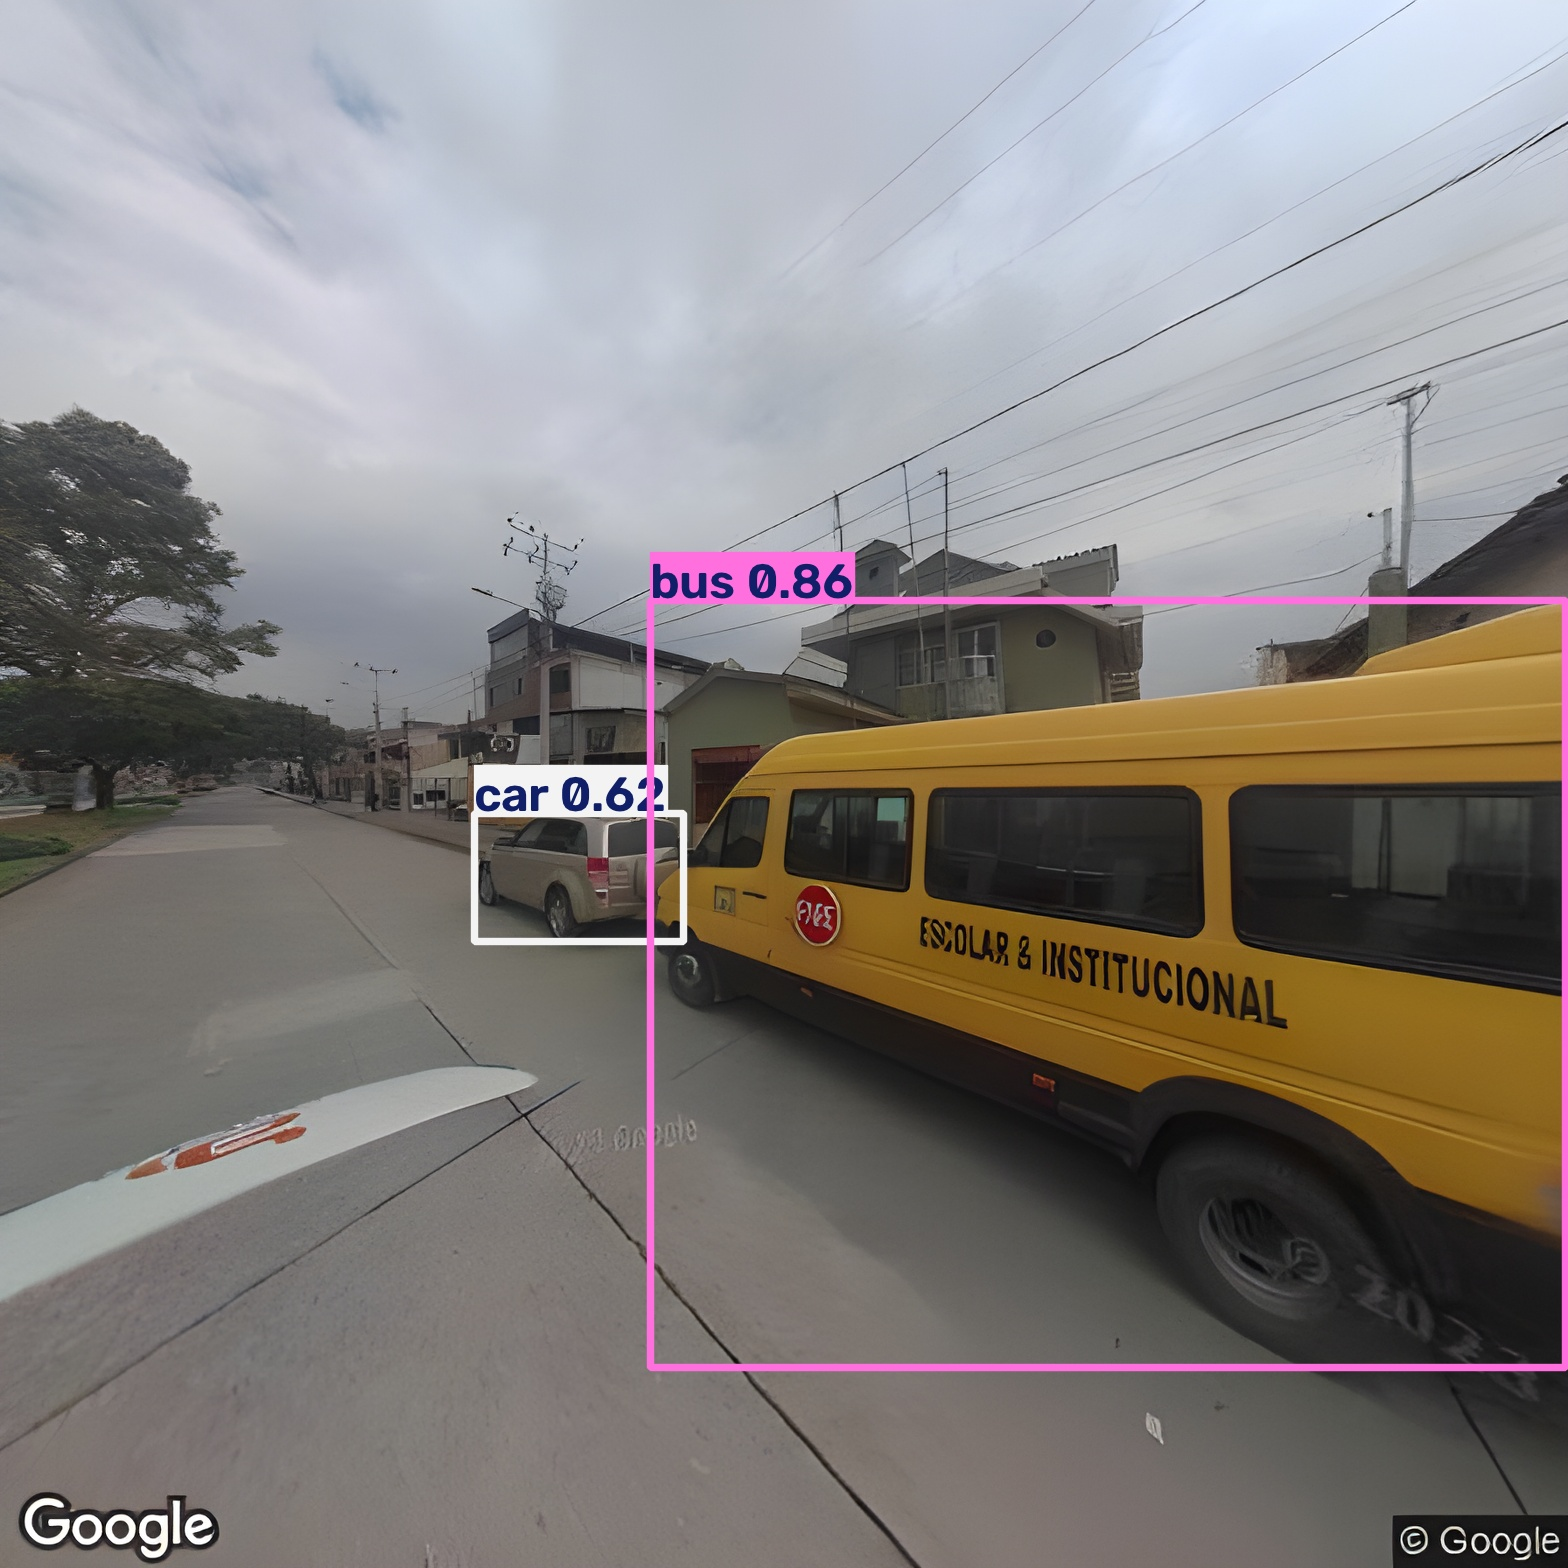

In [7]:
from PIL import Image

resultado.save("foto_detectada.jpg")
Image.open("foto_detectada.jpg")

### Leer lo que encontró el modelo

`resultado.boxes` guarda todas las cajas. Con `len` sabemos cuántas hay:

In [8]:
print(len(resultado.boxes))

2


Cada caja guarda dos datos que nos interesan:
- `cls`: el **número** de la categoría (YOLO guarda números, no palabras).
- `conf`: qué tan seguro está, entre 0 y 1.

Para traducir el número a palabra usamos `resultado.names`, que es una **ficha**: la clave es el número y el valor es el nombre.

In [9]:
print(resultado.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

Ahora recorremos las cajas con un `for`. Usamos `int(...)` y `float(...)` porque el modelo entrega los números en un formato propio (se llama *tensor*); así los convertimos en números normales de Python.

In [10]:
for caja in resultado.boxes:
    numero = int(caja.cls)
    nombre = resultado.names[numero]
    confianza = float(caja.conf)
    print(nombre, round(confianza, 2))

bus 0.86
car 0.62


### Tu turno
1. Mira la foto con las cajas. ¿El modelo acertó con la buseta amarilla? ¿Qué nombre le puso?
2. Escribe tú el patrón completo para guardar lo que encontró el modelo en una tabla:
   - Crea una lista vacía llamada `objetos`.
   - Escribe un `for` que recorra `resultado.boxes`.
   - Dentro del `for`, crea una ficha con dos campos: `"objeto"` (el nombre) y `"confianza"` (redondeada a 2 decimales).
   - Agrega la ficha a `objetos` con `append`.
   - Fuera del `for`, convierte `objetos` en una tabla llamada `tabla_una_foto` y muéstrala.

**Si terminas antes:** cambia el nombre del archivo por otra foto de la carpeta (por ejemplo `streetview_98_180_out.png`) y vuelve a ejecutar todo.

In [ ]:
# escribe aquí

## 6. ¿Para quién está hecha la calle?

Ahora tenemos una pregunta de investigación: en estas calles, **¿qué encontramos más: personas o vehículos?**

Para tener la lista de fotos usamos `glob`, que busca archivos por su nombre. `"/*.png"` significa: todos los archivos que terminan en `.png`. El asterisco quiere decir "cualquier cosa".

In [11]:
from glob import glob

fotos = sorted(glob(carpeta + "/*.png"))
print(len(fotos))
print(fotos[:5])

54
['Inteligencia-Artificial-con-python-FLACSO/datos/imagenes/streetview_88_270_out.png', 'Inteligencia-Artificial-con-python-FLACSO/datos/imagenes/streetview_88_90_out.png', 'Inteligencia-Artificial-con-python-FLACSO/datos/imagenes/streetview_89_0_out.png', 'Inteligencia-Artificial-con-python-FLACSO/datos/imagenes/streetview_89_180_out.png', 'Inteligencia-Artificial-con-python-FLACSO/datos/imagenes/streetview_89_270_out.png']


### Un `for` dentro de otro `for`

Ahora tenemos **muchas fotos** y cada foto tiene **muchas cajas**. Por eso usamos dos `for`, uno dentro del otro:

- el de afuera recorre las **fotos**;
- el de adentro recorre las **cajas** de cada foto (es el mismo que escribiste en tu turno anterior).

Fíjate en la sangría: el segundo `for` está más adentro y la ficha, más adentro todavía.

In [13]:
import pandas as pd

detecciones = []

for ruta in fotos:
    resultado = modelo(ruta, verbose=False)[0]
    for caja in resultado.boxes:
        ficha = {
            "foto": ruta.split("/")[-1],
            "objeto": resultado.names[int(caja.cls)],
            "confianza": round(float(caja.conf), 2),
        }
        detecciones.append(ficha)

calle = pd.DataFrame(detecciones)
calle.head(10)

,foto,objeto,confianza
0,streetview_88_270_out.png,car,0.76
1,streetview_88_90_out.png,car,0.65
2,streetview_88_90_out.png,car,0.26
3,streetview_89_270_out.png,truck,0.25
4,streetview_8_180_out.png,truck,0.30
5,streetview_90_270_out.png,car,0.36
6,streetview_91_0_out.png,bus,0.60
7,streetview_91_0_out.png,car,0.58
8,streetview_91_0_out.png,truck,0.50
9,streetview_91_0_out.png,car,0.36


Dos cosas nuevas:
- `verbose=False` le pide al modelo que no imprima mensajes en cada vuelta.
- `ruta.split("/")[-1]` corta la ruta en cada `/` y se queda con el último pedazo: el nombre del archivo. `[-1]` significa "el último".

Ya sabemos hacerle preguntas a la tabla:

In [14]:
calle["objeto"].value_counts()

,count
objeto,
car,41
truck,5
person,4
bus,3
train,1


### El nombre del archivo también es un dato

Mira cómo se llaman las fotos: `streetview_91_270_out.png`. Si lo cortamos en cada `_`:

In [15]:
partes = "streetview_91_270_out.png".split("_")
print(partes)
print("punto:", partes[1])
print("dirección:", partes[2])

['streetview', '91', '270', 'out.png']
punto: 91
dirección: 270


- El segundo pedazo es el **punto** de la calle donde se tomó la foto.
- El tercero es la **dirección** hacia donde mira la cámara: 0, 90, 180 o 270 grados.

Las cuatro fotos de un mismo punto forman una vuelta completa alrededor de ese lugar. Agregamos esas dos columnas a la tabla:

In [16]:
calle["punto"] = calle["foto"].str.split("_").str[1]
calle["direccion"] = calle["foto"].str.split("_").str[2]
calle.head()

,foto,objeto,confianza,punto,direccion
0,streetview_88_270_out.png,car,0.76,88,270
1,streetview_88_90_out.png,car,0.65,88,90
2,streetview_88_90_out.png,car,0.26,88,90
3,streetview_89_270_out.png,truck,0.25,89,270
4,streetview_8_180_out.png,truck,0.30,8,180


`.str.split("_")` hace el mismo corte, pero en todas las filas de la columna a la vez.

Ahora podemos ver cuántos objetos de cada tipo hay **en cada punto**. Usamos una **tabla cruzada**: los puntos en las filas, los objetos en las columnas y, en cada celda, cuántas veces aparece. Es lo mismo que una tabla dinámica en Excel.

In [17]:
por_punto = pd.crosstab(calle["punto"], calle["objeto"])
por_punto

objeto,bus,car,person,train,truck
punto,,,,,
8,0,0,0,0,1
88,0,3,0,0,0
89,0,0,0,0,1
9,0,2,2,0,1
90,0,1,0,0,0
91,2,11,0,0,2
92,0,2,0,0,0
93,1,0,0,0,0
94,0,3,0,0,0


In [ ]:
por_punto.plot(kind="bar", figsize=(10, 4))

### Tu turno
1. Muchas detecciones tienen confianza baja. Crea una tabla llamada `seguras` solo con las filas donde `"confianza"` es mayor o igual a `0.5`. (Recuerda cómo filtramos filas en la clase 3: `tabla[condición]`.)
2. Cuenta los objetos de `seguras` con `value_counts()`. ¿Cuántas personas (`"person"`) y cuántos autos (`"car"`) quedan?
3. Haz la tabla cruzada de `seguras` por punto y su gráfico de barras.

**Para pensar:**
- ¿Cambió mucho el resultado al filtrar? ¿Quién decide dónde poner el corte de 0.5?
- ¿Hay puntos que no aparecen en la tabla? ¿Por qué? (Pista: una foto sin detecciones no genera ninguna ficha.)
- Casi no hay personas. ¿Significa que nadie usa estas calles, o depende de la hora y el día en que pasó el auto de Google?

In [ ]:
# escribe aquí

In [ ]:
# escribe aquí

## 7. Auditoría: ¿qué ve YOLO y qué no?

Hasta ahora usamos el modelo como si fuera una herramienta neutral. Ahora vamos a **auditarlo**: revisar con cuidado qué ve, qué confunde y qué ni siquiera puede nombrar.

YOLO solo conoce las 80 categorías de COCO. Mira la lista completa:

In [ ]:
categorias = list(modelo.names.values())
print(categorias)

COCO es una base de fotos publicada en 2014 por un equipo liderado por Microsoft, armada principalmente con fotos de Flickr. Fíjate qué objetos considera importantes y cuáles no aparecen.

### Tu turno
Mira las fotos de nuestras calles. Además de autos y personas, ¿qué más hay? Revisa si estas palabras están en `categorias`, usando `in`: `"wall"` (muro), `"fence"` (reja), `"pole"` (poste), `"tire"` (llanta), `"traffic light"` (semáforo). Para cada una imprime la palabra y si aparece (`True` o `False`).

**Si terminas antes:** hazlo con un `for` que recorra una lista de palabras.

In [ ]:
# escribe aquí

### Mirar las fotos con las cajas

Elegimos tres puntos muy distintos: una calle abierta (8), una calle residencial con casas y cerramientos (92) y el interior de una tienda de repuestos (89). Este `for` dibuja las cajas en cada foto y la muestra. `display(...)` hace falta para mostrar imágenes dentro de un `for`; sin él, Colab solo mostraría la última.

In [ ]:
elegidas = [
    carpeta + "/streetview_8_90_out.png",
    carpeta + "/streetview_92_0_out.png",
    carpeta + "/streetview_89_180_out.png",
]

for ruta in elegidas:
    resultado = modelo(ruta, verbose=False)[0]
    nombre_salida = ruta.split("/")[-1].replace(".png", "_detectado.jpg")
    resultado.save(nombre_salida)
    display(Image.open(nombre_salida))

### Tu turno: ficha de auditoría
Este es el ejercicio principal de hoy. Para cada una de las tres fotos escribe a mano una ficha con:
- `"foto"`: el nombre del archivo;
- `"lo_que_hay"`: lo que tú ves en la foto;
- `"lo_que_dijo_el_modelo"`: las etiquetas que puso YOLO;
- `"errores"`: qué confundió o qué no vio.

Guarda las tres fichas en una lista llamada `auditoria` y conviértela en tabla.

Ejemplo de una ficha:
```
{"foto": "streetview_89_180_out.png",
 "lo_que_hay": "tienda de repuestos, llantas, cajas de aceite, estanterías",
 "lo_que_dijo_el_modelo": "...",
 "errores": "..."}
```

Fíjate también en la **parte de abajo** de las fotos: ¿qué se ve ahí? ¿El modelo detecta algo en esa zona?

In [ ]:
# escribe aquí

### Para discutir
1. En estas fotos hay muros, rejas, cerramientos y cables por todas partes. Dicen mucho sobre cómo se vive y se protege la vivienda en la ciudad, pero no existen para el modelo. ¿Qué información social se pierde cuando solo contamos lo que está en las 80 categorías?
2. Estas fotos las tomó un auto de Google, en un día y una hora concretos, y no sabemos cuáles. Si usáramos estos datos para decir "en este barrio no camina nadie", ¿qué estaríamos afirmando sin poder sostenerlo?
3. Detectar personas y vehículos en el espacio público es también la base de muchas tecnologías de **vigilancia**. ¿Qué cuidados éticos deberíamos tener al usar estas fotos y estos modelos en una investigación?

Lectura sugerida: DeVries, Misra, Wang y van der Maaten (2019), *Does Object Recognition Work for Everyone?* Compararon sistemas comerciales de reconocimiento de objetos con fotos de hogares de distintos países y niveles de ingreso.

## 8. Resumen

| | Clasificación | Detección (YOLO) |
|---|---|---|
| Pregunta | ¿Qué es esta foto? | ¿Qué hay y dónde está? |
| Respuesta | una lista de etiquetas para la foto completa | una caja por cada objeto |
| Lo que leemos | `"label"` y `"score"` | `caja.cls` y `caja.conf` |
| Lo que conoce | 1000 etiquetas de ImageNet | 80 categorías de COCO |

Y el patrón de siempre, ahora con dos `for`:

| Paso | Código |
|---|---|
| Antes de los `for` | `detecciones = []` |
| Para cada foto | `for ruta in fotos:` → `modelo(ruta)` |
| Para cada caja | `for caja in resultado.boxes:` → ficha → `append` |
| Al final | `pd.DataFrame(detecciones)` |

La próxima clase vamos un paso más allá: en lugar de cajas, el modelo va a marcar el **contorno exacto** de cada objeto (segmentación).